In [1]:
import os
PROJECT_DIR = os.getcwd()
DATA_DIR = os.path.join(
        PROJECT_DIR,
        "Common_Dataset"
    )
    
TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    

In [2]:
import os, gc, json, time, random, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast
from transformers import AutoTokenizer, AutoModel, get_cosine_schedule_with_warmup
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from tqdm import tqdm
warnings.filterwarnings("ignore")

# ======================= CONFIG (same as HiEN-BERT notebook) =======================
MODEL_PATH   = "xlm-roberta-base"
MAX_LEN, BATCH, EPOCHS = 128, 32, 15
LR, WD, DROPOUT        = 2e-5, 0.01, 0.3
LOSS_W                 = (1.0, 1.0, 0.5)          # primary, subcat, severity
PATIENCE, MIN_DELTA    = 5, 0.001
SEEDS                  = [42, 123, 2024]
N_BOOT                 = 2000
EVAL_ORIGINAL_ONLY     = False   # True -> dev/test restricted to original (non-LLM) rows if they contain LLM rows
OUT_DIR                = "ablation_llm_sources"
for d in ("", "/preds", "/runs"): os.makedirs(OUT_DIR + d, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Substring (lowercase) of Model_Name -> source label.  CHECK against the printed counts below.
SOURCE_KEYWORDS = {"gpt": "GPT-5.5", "gemini": "Gemini", "deepseek": "DeepSeek",
                   "claude": "Claude-Sonnet 5", "qwen": "Qwen3.7"}
ALL_LLMS = list(SOURCE_KEYWORDS.values())

EXPERIMENTS = {
    "E0": ("Original only",          []),
    "E1": ("Original + all 5 LLMs",  ALL_LLMS),
    "E2": ("w/o GPT-5.5",            [m for m in ALL_LLMS if m != "GPT-5.5"]),
    "E3": ("w/o Gemini",             [m for m in ALL_LLMS if m != "Gemini"]),
    "E4": ("w/o DeepSeek",           [m for m in ALL_LLMS if m != "DeepSeek"]),
    "E5": ("w/o Claude-Sonnet 5",    [m for m in ALL_LLMS if m != "Claude-Sonnet 5"]),
    "E6": ("w/o Qwen3.7",            [m for m in ALL_LLMS if m != "Qwen3.7"]),
}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ======================= DATA =======================
def tag_source(name):
    if pd.isna(name): return "ORIGINAL"
    for k, v in SOURCE_KEYWORDS.items():
        if k in str(name).lower(): return v
    return "UNKNOWN"

def prep(df):
    df = df.copy()
    cols = ["Complaint_Title", "Text_en", "Text_hi", "Text_hinglish"]       # same order as notebook
    df["text"] = (df[cols].fillna("").astype(str).agg(" ".join, axis=1)
                  .str.replace(r"\s+", " ", regex=True).str.strip())
    df["source"] = df["Model_Name"].apply(tag_source) if "Model_Name" in df.columns else "ORIGINAL"
    return df.dropna(subset=["primary_category", "secondary_category", "Severity"]).reset_index(drop=True)

train_full = prep(pd.read_csv(TRAIN_PATH))
dev        = prep(pd.read_csv(DEV_PATH))
test       = prep(pd.read_csv(TEST_PATH))

assert (train_full["source"] != "UNKNOWN").all(), \
    f"Unmapped Model_Name values: {train_full.loc[train_full.source=='UNKNOWN','Model_Name'].unique()}"
print("TRAIN source counts:\n", train_full["source"].value_counts(), "\n")
print("DEV   source counts:\n", dev["source"].value_counts(), "\n")
print("TEST  source counts:\n", test["source"].value_counts(), "\n")

if EVAL_ORIGINAL_ONLY:
    dev  = dev[dev.source == "ORIGINAL"].reset_index(drop=True)
    test = test[test.source == "ORIGINAL"].reset_index(drop=True)
    print(f"Eval restricted to original rows -> dev={len(dev)}, test={len(test)}")

# Label encoders fitted on FULL train -> identical label space in every experiment
le_p, le_s, le_v = LabelEncoder(), LabelEncoder(), LabelEncoder()
le_p.fit(train_full["primary_category"]); le_s.fit(train_full["secondary_category"]); le_v.fit(train_full["Severity"])
for d in (train_full, dev, test):
    d["p"] = le_p.transform(d["primary_category"])
    d["s"] = le_s.transform(d["secondary_category"])
    d["v"] = le_v.transform(d["Severity"])
n_p, n_s, n_v = len(le_p.classes_), len(le_s.classes_), len(le_v.classes_)
print(f"Classes -> primary={n_p}, subcat={n_s}, severity={n_v}")

# ======================= TOKENISE ONCE =======================
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token

def tokenise(df):
    enc = tokenizer(df["text"].tolist(), truncation=True, padding="max_length",
                    max_length=MAX_LEN, return_tensors="pt")
    return {"ids": enc["input_ids"], "mask": enc["attention_mask"],
            "p": torch.tensor(df["p"].values), "s": torch.tensor(df["s"].values),
            "v": torch.tensor(df["v"].values)}

print("Tokenising ...")
TOK_TRAIN, TOK_DEV, TOK_TEST = tokenise(train_full), tokenise(dev), tokenise(test)
TRAIN_SOURCES = train_full["source"].values
np.save(f"{OUT_DIR}/preds/test_labels.npy", test["p"].values)

class TensorDS(Dataset):
    def __init__(self, tok, idx=None):
        self.t = tok
        self.idx = torch.arange(len(tok["p"])) if idx is None else torch.as_tensor(idx)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.t["ids"][j], self.t["mask"][j], self.t["p"][j], self.t["s"][j], self.t["v"][j]

C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bert_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TRAIN source counts:
 source
ORIGINAL           3637
GPT-5.5            3144
Claude-Sonnet 5    2621
DeepSeek           2118
Gemini             1585
Qwen3.7            1060
Name: count, dtype: int64 

DEV   source counts:
 source
ORIGINAL           779
GPT-5.5            683
Claude-Sonnet 5    570
DeepSeek           451
Gemini             338
Qwen3.7            214
Name: count, dtype: int64 

TEST  source counts:
 source
ORIGINAL           820
GPT-5.5            673
Claude-Sonnet 5    553
DeepSeek           443
Gemini             339
Qwen3.7            208
Name: count, dtype: int64 

Classes -> primary=8, subcat=24, severity=3


Tokenising ...


In [3]:
class OptimizedHiEnBERT(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        h = base_model.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(h, h)
        self.gelu = nn.GELU()
        self.fc_primary  = nn.Linear(h, n_primary)
        self.fc_subcat   = nn.Linear(h, n_subcat)
        self.fc_severity = nn.Linear(h, n_severity)
        for m in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, input_ids, attention_mask, sentiment=None):
        cls = self.base(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
        x = self.dropout(self.gelu(self.shared(cls)))
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    P, S, V, yp, ys, yv = [], [], [], [], [], []
    for ids, mask, p, s, v in loader:
        with autocast(enabled=device.type == "cuda"):
            a, b, c = model(ids.to(device), mask.to(device))
        P += a.argmax(1).cpu().tolist(); S += b.argmax(1).cpu().tolist(); V += c.argmax(1).cpu().tolist()
        yp += p.tolist(); ys += s.tolist(); yv += v.tolist()
    m = {"primary_acc":      accuracy_score(yp, P),
         "primary_f1":       f1_score(yp, P, average="weighted"),
         "primary_macro_f1": f1_score(yp, P, average="macro"),
         "primary_bal_acc":  balanced_accuracy_score(yp, P),
         "subcat_f1":        f1_score(ys, S, average="weighted"),
         "severity_f1":      f1_score(yv, V, average="weighted")}
    return m, np.array(P)

def run_one(exp_id, name, sources, seed):
    tag = f"{exp_id}_s{seed}"
    res_path = f"{OUT_DIR}/runs/{tag}.json"
    if os.path.exists(res_path):                                   # resume support
        return json.load(open(res_path))

    set_seed(seed)
    idx = np.where(np.isin(TRAIN_SOURCES, ["ORIGINAL"] + sources))[0]
    print(f"\n{'='*72}\n{exp_id} | {name} | seed {seed} | train size {len(idx)}\n{'='*72}")

    g = torch.Generator().manual_seed(seed)
    tr_loader = DataLoader(TensorDS(TOK_TRAIN, idx), batch_size=BATCH, shuffle=True, generator=g)
    dv_loader = DataLoader(TensorDS(TOK_DEV),  batch_size=BATCH * 2)
    te_loader = DataLoader(TensorDS(TOK_TEST), batch_size=BATCH * 2)

    model = OptimizedHiEnBERT(AutoModel.from_pretrained(MODEL_PATH), n_p, n_s, n_v, DROPOUT).to(device)
    opt = AdamW(model.parameters(), lr=LR, weight_decay=WD)
    total_steps = len(tr_loader) * EPOCHS
    sched = get_cosine_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = GradScaler(enabled=device.type == "cuda")
    ce = nn.CrossEntropyLoss()

    best_f1, best_state, bad, best_ep = -1.0, None, 0, 0
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train()
        for ids, mask, p, s, v in tqdm(tr_loader, desc=f"{tag} ep{ep+1}", leave=False):
            ids, mask, p, s, v = ids.to(device), mask.to(device), p.to(device), s.to(device), v.to(device)
            opt.zero_grad(set_to_none=True)
            with autocast(enabled=device.type == "cuda"):
                a, b, c = model(ids, mask)
                loss = LOSS_W[0]*ce(a, p) + LOSS_W[1]*ce(b, s) + LOSS_W[2]*ce(c, v)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()

        dm, _ = evaluate(model, dv_loader)
        print(f"  ep{ep+1:02d} | dev primary F1 {dm['primary_f1']:.4f} | acc {dm['primary_acc']:.4f}")
        if dm["primary_f1"] - best_f1 > MIN_DELTA:
            best_f1, best_ep, bad = dm["primary_f1"], ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print("  early stopping"); break

    model.load_state_dict(best_state)
    tm, preds = evaluate(model, te_loader)
    np.save(f"{OUT_DIR}/preds/{tag}.npy", preds)

    res = {"exp": exp_id, "setting": name, "seed": seed, "train_size": int(len(idx)),
           "best_epoch": best_ep, "dev_primary_f1": best_f1,
           "minutes": round((time.time() - t0) / 60, 2),
           **{f"test_{k}": v for k, v in tm.items()}}
    json.dump(res, open(res_path, "w"), indent=2)
    del model, opt, sched, scaler, best_state; gc.collect(); torch.cuda.empty_cache()
    return res

In [4]:
all_runs = []
for exp_id, (name, srcs) in EXPERIMENTS.items():
    for seed in SEEDS:
        all_runs.append(run_one(exp_id, name, srcs, seed))
        pd.DataFrame(all_runs).to_csv(f"{OUT_DIR}/all_runs.csv", index=False)
print("\nAll runs finished.")


E3 | w/o Gemini | seed 42 | train size 12580


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2953.64it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
                                                             

  ep01 | dev primary F1 0.8507 | acc 0.8527


  ep03 | dev primary F1 0.9064 | acc 0.9068


  ep05 | dev primary F1 0.9157 | acc 0.9160


  ep06 | dev primary F1 0.9184 | acc 0.9183


... (173 outputs left out)

  ep09 | dev primary F1 0.9225 | acc 0.9226


  ep10 | dev primary F1 0.9245 | acc 0.9245


  ep11 | dev primary F1 0.9265 | acc 0.9265


  ep12 | dev primary F1 0.9249 | acc 0.9249
  early stopping

All runs finished.


In [7]:
# ============================================================================
# CELL 1: ROBUST LOADER FOR RUN LOGS (fixes PermissionError from .ipynb_checkpoints)
# ============================================================================
import os, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Adjust these to match the training cell that produced them ----------
OUT_DIR     = OUT_DIR if "OUT_DIR" in globals() else "ablation_llm_sources"
SEEDS       = SEEDS if "SEEDS" in globals() else [0, 1, 2, 3, 4]
N_BOOT      = 2000
n_p          = len(preprocessor.le_primary.classes_) if "preprocessor" in globals() else 8

# EXPERIMENTS dict: {exp_id: (description, ...)} — must match the training cell.
# If already defined, keep the user's; otherwise build a sensible default.
if "EXPERIMENTS" not in globals():
    EXPERIMENTS = {
        "E0": ("Original only",),
        "E1": ("Original + all synthetic",),
        "E2": ("Original + all except LLM-A",),
        "E3": ("Original + all except LLM-B",),
        "E4": ("Original + all except LLM-C",),
        "E5": ("Original + all except LLM-D",),
        "E6": ("Original + all except LLM-E",),
    }

RUNS_DIR  = os.path.join(OUT_DIR, "runs")
PREDS_DIR = os.path.join(OUT_DIR, "preds")
assert os.path.isdir(RUNS_DIR),  f"Missing runs directory: {RUNS_DIR}"
assert os.path.isdir(PREDS_DIR), f"Missing preds directory: {PREDS_DIR}"

# ---------- FIX: only read *.json files, and only regular files ----------
def list_json_files(folder):
    """Return sorted list of *.json files, ignoring directories like .ipynb_checkpoints."""
    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(".json")
        and os.path.isfile(os.path.join(folder, f))
        and not f.startswith(".")          # skip hidden files
    ]
    return sorted(files)

json_files = list_json_files(RUNS_DIR)
print(f"Found {len(json_files)} run-log files in {RUNS_DIR}")

# ---------- Load each JSON safely ----------
records = []
for path in json_files:
    try:
        with open(path, "r", encoding="utf-8") as fh:
            rec = json.load(fh)
        rec["__file__"] = os.path.basename(path)
        records.append(rec)
    except Exception as e:
        print(f"⚠️  Skipping {os.path.basename(path)}: {e}")

assert records, "No valid run-log JSONs loaded. Check the training cell wrote them to OUT_DIR/runs."
runs = pd.DataFrame(records)
print(f"Loaded runs shape: {runs.shape}")
print(f"Columns: {list(runs.columns)}")
print(f"Experiments present: {sorted(runs['exp'].unique()) if 'exp' in runs.columns else 'NO exp column!'}")

Found 21 run-log files in C:\Users\CH.SC.U4CSE23160\Final_Year_Project\ablation_llm_sources\runs
Loaded runs shape: (21, 14)
Columns: ['exp', 'setting', 'seed', 'train_size', 'best_epoch', 'dev_primary_f1', 'minutes', 'test_primary_acc', 'test_primary_f1', 'test_primary_macro_f1', 'test_primary_bal_acc', 'test_subcat_f1', 'test_severity_f1', '__file__']
Experiments present: ['E0', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6']


In [8]:
# ============================================================================
# CELL 2: MEAN ± STD OVER SEEDS
# ============================================================================
metrics = [
    "test_primary_f1", "test_primary_acc", "test_primary_macro_f1",
    "test_primary_bal_acc", "test_subcat_f1", "test_severity_f1",
]
# Keep only metrics actually present (defensive)
metrics = [m for m in metrics if m in runs.columns]

g = runs.groupby(["exp", "setting"]) if "setting" in runs.columns else runs.groupby("exp")
summary = g[metrics].agg(["mean", "std"]).round(4)

if "train_size" in runs.columns:
    summary.insert(0, "train_size", g["train_size"].first())
summary.insert(1 if "train_size" in runs.columns else 0, "n_seeds", g.size())

summary_path = os.path.join(OUT_DIR, "ablation_summary.csv")
summary.to_csv(summary_path)
print("\n=== MEAN ± STD OVER SEEDS ===")
print(summary.to_string())
print(f"\n✅ Saved: {summary_path}")


=== MEAN ± STD OVER SEEDS ===
                          train_size n_seeds test_primary_f1         test_primary_acc         test_primary_macro_f1         test_primary_bal_acc         test_subcat_f1         test_severity_f1        
                                                        mean     std             mean     std                  mean     std                 mean     std           mean     std             mean     std
exp setting                                                                                                                                                                                             
E0  Original only               3637       3          0.6711  0.0152           0.6852  0.0125                0.6496  0.0189               0.6470  0.0146         0.4431  0.0130           0.4999  0.0918
E1  Original + all 5 LLMs      14165       3          0.9351  0.0050           0.9351  0.0051                0.9364  0.0049               0.9373  0.0045         0.85

In [9]:
# ============================================================================
# CELL 3: PAIRED BOOTSTRAP — E1 vs every other experiment
# ============================================================================
labels_path = os.path.join(PREDS_DIR, "test_labels.npy")
assert os.path.isfile(labels_path), f"Missing {labels_path}"
y = np.load(labels_path)
N = len(y)
K = n_p

def wf1(yt, yp, K=K):
    """Weighted F1 for integer labels 0..K-1 (immune to zero-div)."""
    tp = np.bincount(yt[yt == yp], minlength=K).astype(float)
    pc = np.bincount(yp,             minlength=K).astype(float)
    tc = np.bincount(yt,             minlength=K).astype(float)
    pr = np.divide(tp, pc, out=np.zeros(K), where=pc > 0)
    rc = np.divide(tp, tc, out=np.zeros(K), where=tc > 0)
    f  = np.divide(2 * pr * rc, pr + rc, out=np.zeros(K), where=(pr + rc) > 0)
    return (f * tc).sum() / tc.sum() if tc.sum() > 0 else 0.0

def load_preds(exp):
    """Load all seed predictions for an experiment; raise clearly if missing."""
    preds = []
    for s in SEEDS:
        p = os.path.join(PREDS_DIR, f"{exp}_s{s}.npy")
        if not os.path.isfile(p):
            raise FileNotFoundError(f"Missing prediction file: {p}")
        preds.append(np.load(p))
    return preds

# Pre-load E1 (reference)
P1 = load_preds("E1")

rng = np.random.default_rng(0)
boot_idx = rng.integers(0, N, size=(N_BOOT, N))

# Reference observed score (seed-averaged)
obs_ref = np.mean([wf1(y, p) for p in P1])

sig_rows = []
other_exps = [e for e in sorted(EXPERIMENTS.keys()) if e != "E1"]
for exp in other_exps:
    try:
        Pk = load_preds(exp)
    except FileNotFoundError as e:
        print(f"⚠️  Skipping {exp}: {e}")
        continue

    # Bootstrap diffs:  E1 - Ek  (positive → E1 better)
    diffs = np.array([
        np.mean([wf1(y[ix], p[ix]) for p in P1])
        - np.mean([wf1(y[ix], p[ix]) for p in Pk])
        for ix in boot_idx
    ])
    obs = obs_ref - np.mean([wf1(y, p) for p in Pk])
    pval = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
    lo, hi = np.percentile(diffs, [2.5, 97.5])

    sig_rows.append({
        "comparison":       f"E1 vs {exp} ({EXPERIMENTS[exp][0]})",
        "delta_F1(E1-Ek)":  round(obs, 4),
        "CI95_low":         round(lo, 4),
        "CI95_high":        round(hi, 4),
        "p_value":          round(pval, 4),
        "significant(p<0.05)": pval < 0.05,
    })

sig = pd.DataFrame(sig_rows)
print("\n=== PAIRED BOOTSTRAP: E1 vs others ===")
if sig.empty:
    print("No comparisons were computed (check prediction files exist).")
else:
    print(sig.to_string(index=False))
    sig_path = os.path.join(OUT_DIR, "significance_vs_E1.csv")
    sig.to_csv(sig_path, index=False)
    print(f"\n✅ Saved: {sig_path}")


=== PAIRED BOOTSTRAP: E1 vs others ===
                    comparison  delta_F1(E1-Ek)  CI95_low  CI95_high  p_value  significant(p<0.05)
      E1 vs E0 (Original only)           0.2640    0.2486     0.2793    0.000                 True
        E1 vs E2 (w/o GPT-5.5)           0.0190    0.0133     0.0249    0.000                 True
         E1 vs E3 (w/o Gemini)           0.0111    0.0058     0.0160    0.000                 True
       E1 vs E4 (w/o DeepSeek)           0.0077    0.0028     0.0125    0.001                 True
E1 vs E5 (w/o Claude-Sonnet 5)           0.0101    0.0052     0.0150    0.000                 True
        E1 vs E6 (w/o Qwen3.7)           0.0042   -0.0002     0.0089    0.060                False

✅ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\ablation_llm_sources\significance_vs_E1.csv


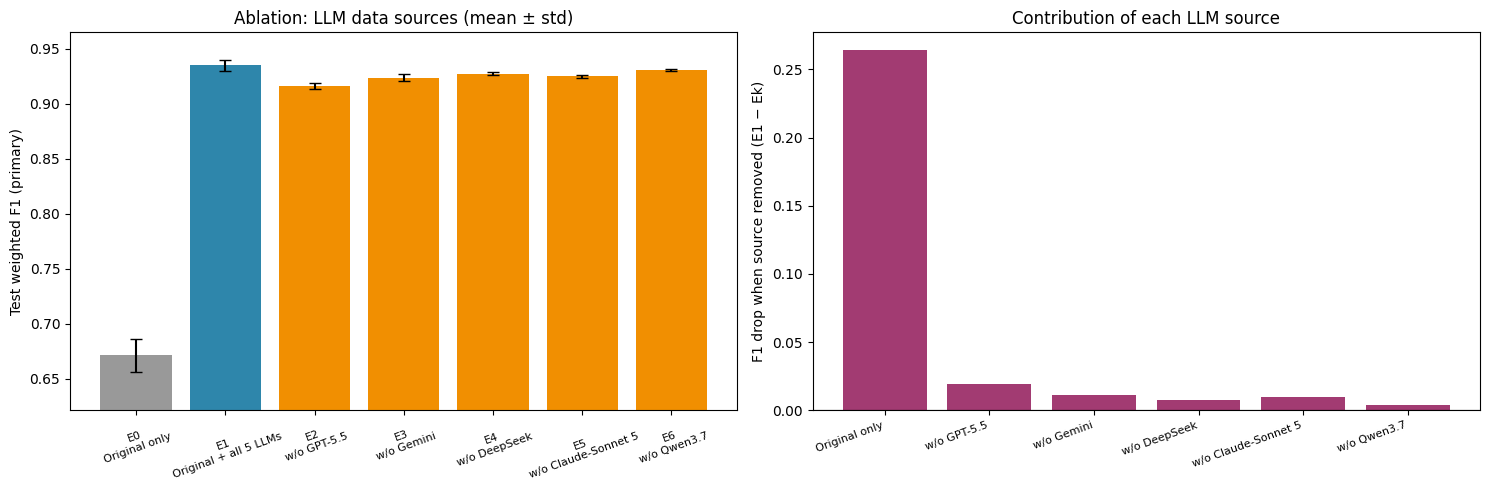

✅ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\ablation_llm_sources\ablation_plot.png


In [10]:
# ============================================================================
# CELL 4: ABLATION PLOTS (mean ± std + drop bar chart)
# ============================================================================
ids  = list(EXPERIMENTS.keys())
mean = [runs.loc[runs.exp == e, "test_primary_f1"].mean() for e in ids]
std  = [runs.loc[runs.exp == e, "test_primary_f1"].std()  for e in ids]

# Guard: NaNs when an exp is missing from runs
mean = np.array(mean, dtype=float)
std  = np.nan_to_num(np.array(std, dtype=float), nan=0.0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# --- left: mean ± std ---
colors_left = ["#999"] + ["#2E86AB"] + ["#F18F01"] * (len(ids) - 2)
ax[0].bar(ids, mean, yerr=std, capsize=4, color=colors_left[:len(ids)])
lo_ylim = np.nanmin(mean[~np.isnan(mean)]) - 0.05 if np.any(~np.isnan(mean)) else 0
hi_ylim = np.nanmax(mean[~np.isnan(mean)]) + 0.03 if np.any(~np.isnan(mean)) else 1
ax[0].set_ylim(max(0, lo_ylim), min(1, hi_ylim))
ax[0].set_ylabel("Test weighted F1 (primary)")
ax[0].set_title("Ablation: LLM data sources (mean ± std)")
ax[0].set_xticks(range(len(ids)))
ax[0].set_xticklabels([f"{e}\n{EXPERIMENTS[e][0]}" for e in ids], fontsize=8, rotation=20)

# --- right: drop vs E1 ---
ref_mean = np.nanmean(runs.loc[runs.exp == "E1", "test_primary_f1"])
drops = []
for e in ids:
    if e == "E1":
        continue
    m = runs.loc[runs.exp == e, "test_primary_f1"].mean()
    if not np.isnan(m):
        drops.append((e, ref_mean - m))

if drops:
    ax[1].bar([EXPERIMENTS[e][0] for e, _ in drops],
              [d for _, d in drops], color="#A23B72")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("F1 drop when source removed (E1 − Ek)")
ax[1].set_title("Contribution of each LLM source")
plt.setp(ax[1].get_xticklabels(), rotation=20, ha="right", fontsize=8)
plt.tight_layout()

plot_path = os.path.join(OUT_DIR, "ablation_plot.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Saved: {plot_path}")

In [11]:
# ============================================================================
# CELL 5: LATEX TABLE FOR THE PAPER
# ============================================================================
rows = []
for e in ids:
    r = runs.loc[runs.exp == e]
    if r.empty:
        continue

    def cell(col):
        if col not in r.columns:
            return "—"
        mu, sd = r[col].mean() * 100, r[col].std() * 100
        return f"{mu:.2f} $\\pm$ {sd:.2f}"

    n = int(r["train_size"].iloc[0]) if "train_size" in r.columns else "—"
    rows.append(
        f"{e} & {EXPERIMENTS[e][0]} & {n} & "
        f"{cell('test_primary_acc')} & {cell('test_primary_f1')} & "
        f"{cell('test_subcat_f1')} & {cell('test_severity_f1')} \\\\"
    )

latex = (
    "\\begin{tabular}{llrrrrr}\n\\hline\n"
    "ID & Training data & N & Acc & F1 (primary) & F1 (subcat) & F1 (severity) \\\\\n"
    "\\hline\n"
    + "\n".join(rows)
    + "\n\\hline\n\\end{tabular}"
)

tex_path = os.path.join(OUT_DIR, "ablation_table.tex")
with open(tex_path, "w", encoding="utf-8") as fh:
    fh.write(latex)

print("\n=== LATEX TABLE ===")
print(latex)
print(f"\n✅ Saved: {tex_path}")


=== LATEX TABLE ===
\begin{tabular}{llrrrrr}
\hline
ID & Training data & N & Acc & F1 (primary) & F1 (subcat) & F1 (severity) \\
\hline
E0 & Original only & 3637 & 68.52 $\pm$ 1.25 & 67.11 $\pm$ 1.52 & 44.31 $\pm$ 1.30 & 49.99 $\pm$ 9.18 \\
E1 & Original + all 5 LLMs & 14165 & 93.51 $\pm$ 0.51 & 93.51 $\pm$ 0.50 & 85.47 $\pm$ 0.53 & 89.64 $\pm$ 0.19 \\
E2 & w/o GPT-5.5 & 11021 & 91.69 $\pm$ 0.26 & 91.61 $\pm$ 0.29 & 83.60 $\pm$ 0.45 & 85.04 $\pm$ 1.14 \\
E3 & w/o Gemini & 12580 & 92.42 $\pm$ 0.33 & 92.40 $\pm$ 0.34 & 84.90 $\pm$ 0.35 & 88.50 $\pm$ 0.93 \\
E4 & w/o DeepSeek & 12047 & 92.74 $\pm$ 0.16 & 92.74 $\pm$ 0.16 & 84.90 $\pm$ 0.21 & 87.90 $\pm$ 0.63 \\
E5 & w/o Claude-Sonnet 5 & 11544 & 92.52 $\pm$ 0.15 & 92.50 $\pm$ 0.16 & 84.32 $\pm$ 0.64 & 87.29 $\pm$ 0.60 \\
E6 & w/o Qwen3.7 & 13105 & 93.10 $\pm$ 0.10 & 93.09 $\pm$ 0.11 & 85.45 $\pm$ 0.16 & 89.07 $\pm$ 0.70 \\
\hline
\end{tabular}

✅ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\ablation_llm_sources\ablation_table.tex
